# Hybrid DPD Study Noteboob

This notebook studies digital predistortion (DPD) with a synthetic baseband power amplifier model inspired by:

> Mohammad Abdollah Chalaki, Emma Gu, Ahmed Ben Ayed, Patrick Mitran, and Slim Boumaiza, "Robust Digital Predistortion of Load-Modulated Power Amplifiers Under Varying Signal Conditions," IEEE Microwave Magazine, 2026.

The goal is to learn the main idea rather than claim an reproduction of the measured LMBA hardware results.

## What This Notebook Covers

1. Generate multi-carrier OFDM that resembles the paper's varing carriers configuration
2. Build a CRV-insipired DPD basis and a synthetic memory PA.
3. Run sanity check before trusting any performance curves
4. Compare indirect, direct-refinement and hybrid learning
5. Explore PAPR reduction, coefficients pruning, bandwidth-limited observation and configuration-robust training

## Important Limitation

This paper is measurement driven and doesn't provide the full LMBA behavioral law or raw DUT IQ captures. The code below therefore uses a study-oriented synthetic PA that preserves the paper's algorithmic idea without claiming hardware faithful reproduction

In [1]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np

NOTEBOOK_SRC = Path("C:\dev\projee\dpd_of_load_modulated_pa\study_dpd.ipynb")
if str(NOTEBOOK_SRC) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_SRC))

import dpd_utils as du

du = importlib.reload(du)

np.random.seed(0)

_style_candidates = ["seaborn-v0_8-whitegrid", "seaborn-whitegrid", "ggplot"]
_style = next((s for s in _style_candidates if s in plt.style.available), None)
if _style is not None:
    plt.style.use(_style)
else:
    print("No seaborn-style stylesheet found; using matplotlib default style")

print(f"Using dpd_utils from: {du.__file__}")
print("Random seed fixed to 0 for reproducibility")

<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:8: SyntaxWarning: invalid escape sequence '\d'
  NOTEBOOK_SRC = Path("C:\dev\projee\dpd_of_load_modulated_pa\study_dpd.ipynb")


Using dpd_utils from: c:\dev\projee\dpd_of_load_modulated_pa\dpd_utils.py
Random seed fixed to 0 for reproducibility


## 1. Paper Framing

The paper studies a load-modulated balanced amplifier (LMBA) under multiple wideband carrier configurations. The winning approach combines:

- a complexitiy-reduced Voltarra (CRV) predistorter
- hybrid indirect/direct learning
- coefficient pruning
- observation-bandwidth-aware training, and
- training across multiple carrier configuration to build one robust model

The notebook below mirrors that structure, but uses synthetic PA so the experiements are fully runnable without RF hardware

waveform | mask | papr_db | samples
--- | --- | --- | ---
single_carrier | (0, 0, 1, 0, 0) | 9.016 | 27648.000
three_carrier | (1, 0, 1, 1, 0) | 9.768 | 27648.000
five_carrier | (1, 1, 1, 1, 1) | 11.401 | 27648.000


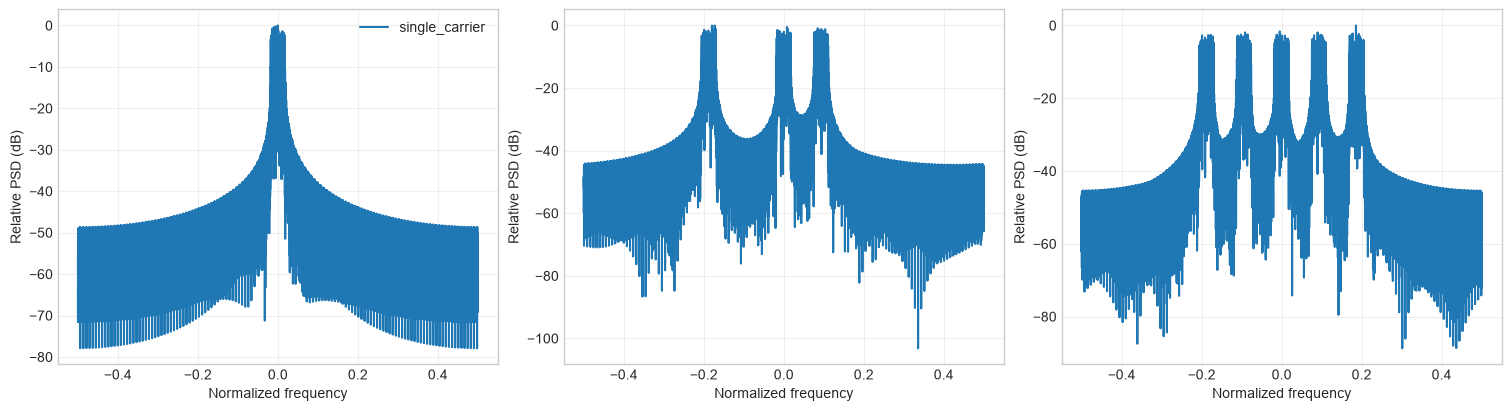

In [2]:
# Dictionary of carrier masks and their corresponding waveforms
carrier_masks = {
    "single_carrier": [0,0,1,0,0],
    "three_carrier": [1,0,1,1,0],
    "five_carrier": [1,1,1,1,1]
}

waveform = {}

#iterating a dictionary, enumerate(), and tuple unpacking
#seed gets the counter from enumerate()
for seed, (name, mask) in enumerate (carrier_masks.items(),start=1):
    rng = du.make_rng(seed)
    waveform[name] = du.generate_multicarrier_ofdm(mask,rng,num_symbols=24)

study_wf = waveform["three_carrier"]

fig, axes = plt.subplots(1, 3, figsize=(15,4), constrained_layout=True)
rows = []
for ax, (name,wf) in zip (axes, waveform.items()):
    du.plot_spectrum(wf.samples, label=name, ax=ax)
    rows.append(
        {
            "waveform": name,
            "mask": str(wf.mask),
            "papr_db": du.measure_papr_db(wf.samples),
            "samples": float(len(wf.samples)),
        }
    )

axes[0].legend()
print(du.rows_to_table(rows))

## 2. Synthetic PA And CRV-Inspired Basis

The source paper uses CRV DPD model and a measured LMBA DUT. Here we replace DUT with a synthetic memory polymonimial PA that has:

- AM/AM compression
- mid AM/PM distortion, and
- short memory/cross memory effects

The DPD basis includes:

- linear memory terms
- aligned odd-order non-linear memory term, and
- lag/lead enevelop-coupled cross terms.

## 2.1 PA modeling
PA behavioral model can be broadly classified into memoryless, memory polynomial, Volterra-based and neural/data driven model
1. Memoryless polynomial model

    General model:\
    $y[n] = \sum_{k=1}^{n} a_k\, x[n]\,\lvert x[n]\rvert^{k-1}$

    Only odd model:\
    $y[n] = \sum_{k=\mathrm{odd}}^{n} a_k\, x[n]\,\lvert x[n]\rvert^{k-1}$

2. Saleh Model (Memoryless)
    
    Popular for TWTA or satellite TWTA
    
    TWTA: traveling waves tube amplifier, a vacumm-eletronics power amplifiers, used in satellites, radar, deep space communications, unlike transistor PA, the amplification comes from the interaction between RF waves and electron beam

    AM/AM:\
    $G(r) = \dfrac{\alpha_a r}{1+\beta_a r^2}$

    AM/PM:\
    $\Phi(r) = \dfrac{\alpha_{\phi} r^2}{1+\beta_{\phi} r^2}$

    where\
    $r = \lvert x \rvert$

    Output\
    $y = G(r)\, e^{j \angle x + \Phi(r)}$

3. Wiener Model

    Linear filter followed by non-linear block\
    $x(n) \rightarrow H(z) \rightarrow f(\cdot) \rightarrow y(n)$

4. Hammerstein Model

    The opposite ordering from Wiener model

    Non-linear block followed by linear filter\
    $x(n) \rightarrow f(\cdot) \rightarrow H(z) \rightarrow y(n)$

5. Wiener-Hammerstein Model\
    $x(n) \rightarrow H_1(z) \rightarrow f(\cdot) \rightarrow H_2(z) \rightarrow y(n)$

6. Volterra Series Model

    The "gold standard" behavioral model.

    General form:\
    $y(n) = \sum_p \sum_{m_1,\ldots,m_p} h_p(m_1, m_2, \ldots, m_p) \prod_i x[n-m_i]$

    Advantages:
        Very accurate
        Can represent alsmot any wealy nonlinear dynamic system

7. Memory Polynomial (MP)

    Most popular PA model today\
    $y[n] = \sum_{p}^{P} \sum_{m=0}^{M} a_{p,m}\, x[n-m]\,\lvert x[n-m]\rvert^{p-1}$

    where $P$ is polynomial order and $M$ is memory depth

    Advantages:
        Excellent complexity/performance tradeoff
        Easy least-sqaure estimation
        Industry standard

8. Gneralized Memory Polynomial (GMP)

    Adds lagging and leading envelop teams\
    $y(n) = \text{MP terms} + \text{cross-memory terms}$

    Example:\
    $x[n-m]\,\lvert x[n-m-l]\rvert^{p-1}$

    It can capture eletrical memory, thermal memory and dynamic AM-AM distortion

9. Dynamic Deviation Reduction (DDR)

    Instead of all Volterra kernels, use selected interaction

10. Complexity Reduced Volterra (CRV)

    Keep only dominant Volterra basis functions

For practical DPD system
| Model                     | Usage                     |
| ------------------------- | ------------------------- |
| Memory Polynomial (MP)    | Extremely common          |
| GMP                       | Industry workhorse        |
| CRV                       | High-performance systems  |
| Volterra                  | Benchmark/reference       |
| Neural DPD                | Active research           |
| Wiener/Hammerstein        | Academic modeling         |
| Saleh                     | Satellite/TWTA studies    |


Additional Notes:
1. Why are odd orders usually used?

    Using sinusoid signal as an examples, the second order component introduces DC offset and 2nd order harmonics and third order gives fundamental frequencies and 3rd order harmonics.\
    $x(n) = A \cos(\omega t)$\
    $x^2(n) = A^2/2 + (A^2/2)\cos(2\omega t)$\
    $x^3(n) = (3A^3/4)\cos(\omega t) + (A^3/4)\cos(3\omega t)$

    In general, even order introduces DC components, even order harmonics and frequency components far from the desired band. These can be usually filtered by differential circuits, matching network and RF bandpass filter

    Therefore, the odd order terms becomes dominant in such cases

2. What is GaN PA? Gallium-Nitride power amplifier

3. Fully expanded Volterra model for order 3 and memory depth of 1

    $y(n) = \sum_p \sum_{m_1,\ldots,m_p} h_p(m_1, m_2, \ldots, m_p) \prod_i x[n-m_i]$\
    $y(n) = y_1[n] + y_2[n] + y_3[n]$

    where\
    $y_1(n) = \sum_{m_1=0}^{1} h_1(m_1)\, x(n - m_1) = h_1(0)\, x[n] + h_1(1)\, x[n-1]$

    $\begin{aligned} y_2(n) &= \sum_{m_1=0}^{1} \sum_{m_2=0}^{1} h_2(m_1, m_2)\, x(n - m_1)\, x(n - m_2) \\ &= h_2(0, 0)\, x(n)\, x(n) + h_2(0, 1)\, x(n)\, x(n - 1) \\ &\quad + h_2(1, 0)\, x(n - 1)\, x(n) + h_2(1, 1)\, x(n - 1)\, x(n - 1) \end{aligned}$

    $y_3(n) = \sum_{m_1=0}^{1} \sum_{m_2=0}^{1} \sum_{m_3=0}^{1} h_3(m_1, m_2, m_3)\, x(n-m_1)\, x(n-m_2)\, x(n-m_3)$\
    $\ldots$

4. How coefficients are determined?

    Step 1: measure inputs $x[n]$ and outputs $y[n]$ from PA

    Step 2: construct basis functions which depend on PA model, for example MP\
    $\phi_1 = x[n]$\
    $\phi_2 = x[n]\,\lvert x[n]\rvert^{2}$\
    $\phi_3 = x[n]\,\lvert x[n]\rvert^{3}$\
    $\mathbf{\Phi} = \begin{pmatrix} \phi_1(1) & \phi_2(1) & \cdots & \phi_K(1) \\ \phi_1(2) & \phi_2(2) & \cdots & \phi_K(2) \\ \vdots & \vdots & \ddots & \vdots \\ \phi_1(N) & \phi_2(N) & \cdots & \phi_K(N) \end{pmatrix}$

    Step 3: solve least square\
    $\mathbf{y} = \mathbf{\Phi} \mathbf{a}$\
    $\mathbf{a} = (\mathbf{\Phi}^{T} \mathbf{\Phi})^{-1} \mathbf{\Phi}^{T} \mathbf{y}$





Number of CRV-inspired basis function: {basis.shape[1]}
First few basis terms
    linear[m=0]
    linear[m=1]
    linear[m=2]
    aligned[p=3,m=0]
    aligned[p=3,m=1]
    aligned[p=3,m=2]
    aligned[p=5,m=0]
    aligned[p=5,m=1]
    aligned[p=5,m=2]
    lag[p=3,m=0,k=1]


{'papr_db': 9.768285200106494,
 'acpr_db': -21.10333888843963,
 'evm_pct': 15.273514631553335,
 'nmse_db': -11.946586967082393,
 'num_coeffs': 0.0}

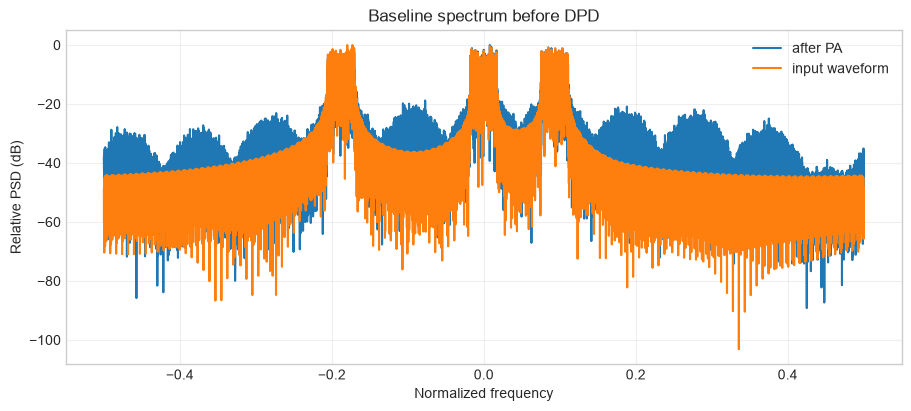

In [3]:
# construct a synthetic pa (Memory Polynomial Model)
pa = du.make_synthetic_pa()
# configuration for bsis
cfg = du.CRVConfig(
    linear_memory = 2,
    nonlinear_orders = (3,5),
    nonlinear_memory = 2,
    cross_memory=1,
    envelope_lags = (1,2),
    include_lead_terms = True,
)
# generated OFDM waveform
x = study_wf.samples
# output of PA
y_baseline = pa(x)
# build basis funcions
basis, basis_names = du.build_crv_basis(x, cfg)
# evaluate performance of PA output in terms of PAPR, ACPR, EVM NMSER
baseline_metrics = du.evaluate_chain(x, study_wf, pa, None)

print("Number of CRV-inspired basis function: {basis.shape[1]}")
print("First few basis terms")
for name in basis_names[:10]:
    print("   ", name)

fig, ax = plt.subplots(figsize = (9,4), constrained_layout = True)
du.plot_spectrum(y_baseline, label="after PA", ax = ax)
du.plot_spectrum(x, label="input waveform", ax=ax)
ax.legend()
ax.set_title("Baseline spectrum before DPD")

baseline_metrics

## 3. Sanity Checks
Three checks:

1. A linear PA should lead to an almost identify predistorter
2. Least square fitting should recover planted coefficients in a noiseless synthetic exmaple
3. The baseline metrics must remian finite

In [4]:
linear_pa = du.make_linear_pa()
linear_model, linear_history = du.run_learning_workflow(
    study_wf,
    linear_pa,
    cfg,
    indirect_iters = 1,
    direct_iters = 1,
)

linear_final = linear_history[-1]
assert linear_final["evm_pct"] < 1e-4
assert linear_final["nmse_db"] < -80

Phi, _ = du.build_crv_basis(x, cfg)
true_coeffs = np.zeros(Phi.shape[1],dtype=complex)
true_coeffs[0] = 1.0
true_coeffs[1] = 0.05
true_coeffs[3] = 0.02 - 0.01j
synthetic_target = Phi @ true_coeffs
estimated_coeffs = du.solve_ridge(Phi, synthetic_target, cfg.ridge)
recovery_rel_err = np.linalg.norm(estimated_coeffs - true_coeffs) / np.linalg.norm(true_coeffs)
assert recovery_rel_err < 1e-5

finite_metric_check = du.evaluate_chain(x, study_wf, pa, None)
assert np.all(np.isfinite(list(finite_metric_check.values())))

sanity_rows = [
    {"check": "linear_PA_identify_evm_pct","value": linear_final["evm_pct"]},
    {"check": "linear_PA_identify_nmse_db","value": linear_final["nmse_db"]},
    {"check": "planted_coeff_recovery_rel_err","value": recovery_rel_err},
    {"check": "baseline_evm_pct","value": finite_metric_check["evm_pct"]},
    {"check": "baseline_acpr_db","value": finite_metric_check["acpr_db"]},
]

print(du.rows_to_table(sanity_rows))

check | value
--- | ---
linear_PA_identify_evm_pct | 0.000
linear_PA_identify_nmse_db | -150.000
planted_coeff_recovery_rel_err | 0.000
baseline_evm_pct | 15.274
baseline_acpr_db | -21.103


## 4. Indirect, direct-refinement and hybrid learning

The paper emphasizes the hybrid learning: indirect learning gives a fast coarse estimate, and direct learning refines it. We reproduce that workflow on the synthetic PA

The comparisons below are intentionally qualitative:
- `indirect_only`: two indirect-learning passes
- `direct_refinement`: direct updates applied to the indirect model
- `hybrid`: two indirect learning followed by two direct refinement

model | papr_db | acpr_db | evm_pct | nmse_db | num_coeffs
--- | --- | --- | --- | --- | ---
baseline | 9.768 | -21.103 | 15.274 | -11.947 | 0.000
indirect_only | 8.791 | -23.825 | 7.442 | -16.146 | 25.000
direct_refinement | 8.355 | -24.921 | 2.072 | -26.277 | 25.000
hybrid | 8.355 | -24.921 | 2.072 | -26.277 | 25.000


Text(0.5, 1.0, 'Output spectrum improvement with hybrid DPD')

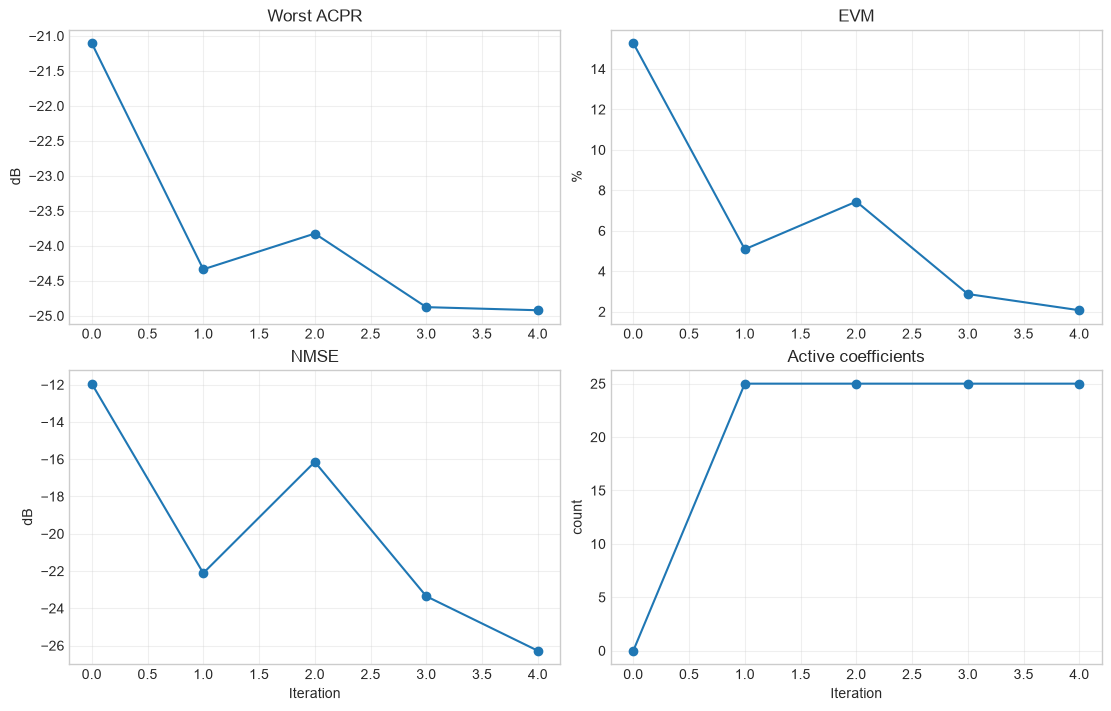

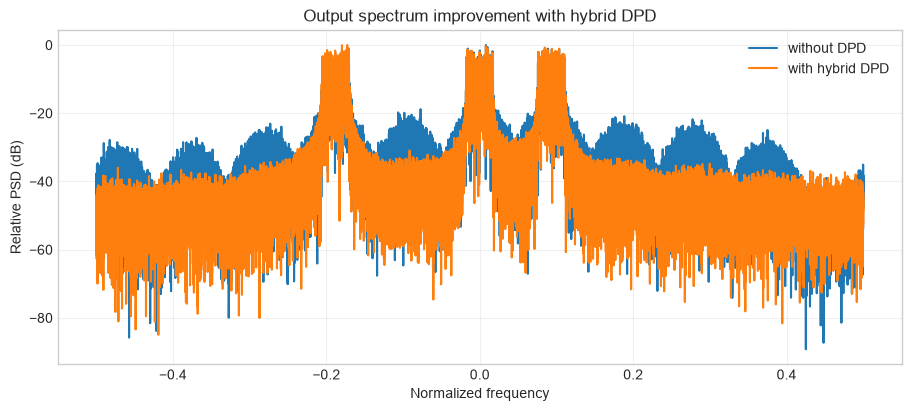

In [11]:
indirect_model, indirect_history = du.run_learning_workflow(
    study_wf,
    pa,
    cfg,
    indirect_iters=2,
    direct_iters=0,
)

# Direct refinement starts from the coarse indirect estimate
direct_model = indirect_model
direct_history = []
for idx in range(2):
    direct_model = du.direct_learning_update(x, pa, direct_model, step_size = 0.65)
    direct_history.append(
        {
        "iteration": float(idx + 1),
        "stage": "direct_only_refinement",
        **du.evaluate_chain(x,study_wf, pa, direct_model),
        }
    )

hybrid_model, hybrid_history = du.run_learning_workflow(
    study_wf,
    pa,
    cfg,
    indirect_iters = 2,
    direct_iters =2,
)

comparison_rows = [
    {"model": "baseline", **du.evaluate_chain(x, study_wf, pa, None)},
    {"model": "indirect_only", **indirect_history[-1]},
    {"model": "direct_refinement", **direct_history[-1]},
    {"model": "hybrid", **hybrid_history[-1]},
]
print(du.rows_to_table(comparison_rows))

_ = du.plot_learning_history(hybrid_history)

fig, ax = plt.subplots(figsize=(9,4), constrained_layout = True)
du.plot_spectrum(pa(x), label="without DPD", ax=ax)
du.plot_spectrum(pa(du.apply_dpd(x, hybrid_model)), label="with hybrid DPD", ax=ax)
ax.legend()
ax.set_title("Output spectrum improvement with hybrid DPD")

## 5. PAPR Reduction Study

The paper combines DPD with PAPR reduction. Here a simple iterative clipping-and-filtering frontend is used.

**Clipping alone.** Measured on the waveform by itself, clipping can only add error: the clipped signal is a distorted copy of the ideal one, so lower PAPR always costs EVM. The filter works per OFDM symbol on the active subcarriers, so an unclipped signal passes through exactly (EVM = 0) and all the EVM below is caused by clipping.

clip_db | papr_db | evm_pct | nmse_db
--- | --- | --- | ---
inf | 9.768 | 0.000 | -inf
9.000 | 9.389 | 0.498 | -46.554
8.000 | 9.026 | 1.513 | -36.872
7.000 | 8.636 | 3.083 | -30.554
6.000 | 8.301 | 5.364 | -25.604
5.000 | 7.853 | 8.290 | -21.749
4.000 | 7.417 | 11.551 | -18.829


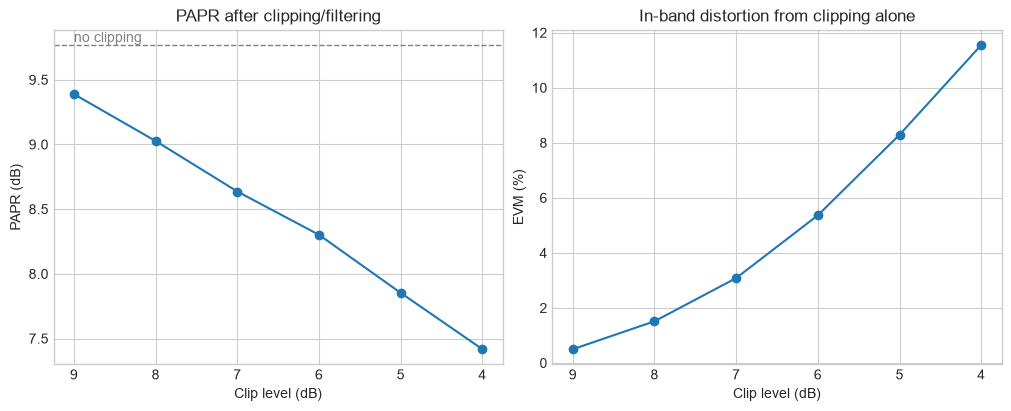

In [6]:
clip_levels_db = [9, 8, 7, 6, 5, 4]
papr_rows = [
    {"clip_db": float("inf"), "papr_db": du.measure_papr_db(x), "evm_pct": 0.0, "nmse_db": float("-inf")}
]

for clip_db in clip_levels_db:
    clipped = du.clipping_filtering(x, study_wf, clip_db)
    papr_rows.append(
        {
            "clip_db": float(clip_db),
            "papr_db": du.measure_papr_db(clipped),
            "evm_pct": du.evm_percent(clipped, study_wf),
            "nmse_db": du.nmse_db(clipped, x),
        }
    )

print(du.rows_to_table(papr_rows))

fig, axes = plt.subplots(1, 2, figsize=(10,4), constrained_layout=True)
axes[0].plot([row["clip_db"] for row in papr_rows[1:]], [row["papr_db"] for row in papr_rows[1:]], marker="o")
axes[0].axhline(papr_rows[0]["papr_db"], color="gray", linestyle="--", linewidth=1)
axes[0].text(clip_levels_db[0], papr_rows[0]["papr_db"], "no clipping", va="bottom", ha="left", color="gray")
axes[0].set_xlabel("Clip level (dB)")
axes[0].set_ylabel("PAPR (dB)")
axes[0].set_title("PAPR after clipping/filtering")
axes[0].invert_xaxis()

axes[1].plot([row["clip_db"] for row in papr_rows[1:]], [row["evm_pct"] for row in papr_rows[1:]], marker="o")
axes[1].set_xlabel("Clip level (dB)")
axes[1].set_ylabel("EVM (%)")
axes[1].set_title("In-band distortion from clipping alone")
axes[1].invert_xaxis()

**Clipping in front of a real PA.** The benefit only shows up once a PA with a hard output limit is in the chain. `make_saturating_pa` is a Wiener model (short memory + Rapp AM/AM + AM/PM) whose output cannot exceed saturation, so no DPD can restore peaks that drive past it. For each clip level the DPD is trained to linearize the PA toward the *clipped* waveform, and the input back-off (IBO) from saturation is swept:

- EVM is measured against the original QAM symbols, so it includes both clipping error and PA/DPD residual.
- `regrowth_acpr_db` counts only the out-of-band power the PA adds. The notebook's `worst_acpr_db` is stuck near -25 dB here because the unwindowed OFDM input already has that much sidelobe power.

At a fixed back-off, clipping still costs EVM: deliberate clipping adds about as much in-band error as letting the PA saturate. What it buys is lower spectral regrowth, because the filter removes the clipping noise out of band while PA saturation does not. In practice the out-of-band spec is usually the binding constraint and there is EVM margin to spare, so clipping lets the PA run at higher average output power (and efficiency). The best clip level is the one that maximizes output power while meeting both specs, not the one with the lowest PAPR.

Highest output power meeting EVM <= 8.0% and regrowth ACPR <= -45.0 dBc
clip | papr_db | min_ibo_db | max_pout_db | evm_pct | regrowth_acpr_db
--- | --- | --- | --- | --- | ---
none | 9.768 | 8.000 | -8.041 | 0.747 | -46.212
8 dB | 9.026 | 7.500 | -7.556 | 2.033 | -45.510
7 dB | 8.636 | 7.500 | -7.540 | 3.385 | -48.373
6 dB | 8.301 | 7.000 | -7.045 | 5.631 | -48.270


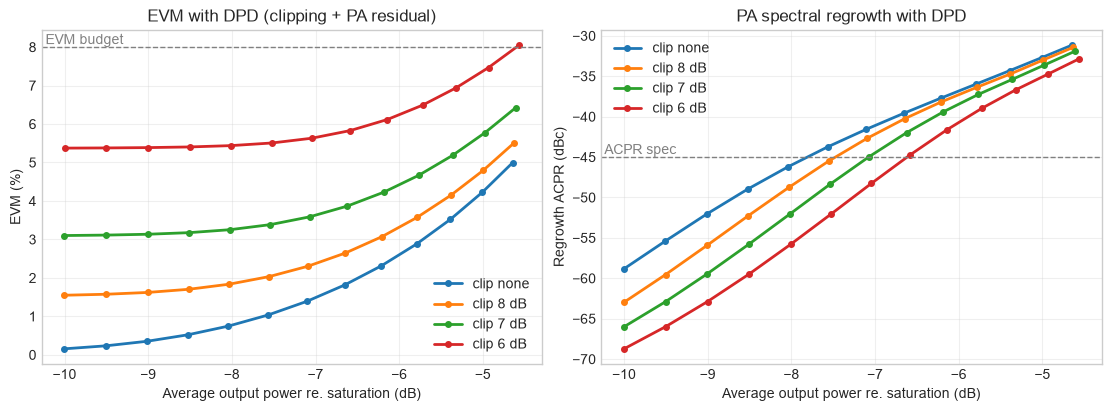

In [7]:
import dataclasses

sat_pa = du.make_saturating_pa()
sweep_clips = [None, 8, 7, 6]
backoffs_db = np.arange(4.0, 10.5, 0.5)
evm_budget_pct = 8.0   # e.g. a 64-QAM-class EVM limit
acpr_spec_db = -45.0   # regrowth limit in the adjacent channel

chain_rows = []
for clip_db in sweep_clips:
    x_cfr = x if clip_db is None else du.clipping_filtering(x, study_wf, clip_db)
    for ibo_db in backoffs_db:
        x_in = x_cfr * 10 ** (-ibo_db / 20)
        wf_in = dataclasses.replace(study_wf, samples=x_in)
        # one indirect pass then direct refinement; a second indirect pass degrades EVM on this PA
        model, history = du.run_learning_workflow(wf_in, sat_pa, cfg, indirect_iters=1, direct_iters=3)
        y = sat_pa(du.apply_dpd(x_in, model))
        chain_rows.append(
            {
                "clip": "none" if clip_db is None else f"{clip_db} dB",
                "papr_db": du.measure_papr_db(x_cfr),
                "ibo_db": float(ibo_db),
                "pout_db": float(du.db10(np.mean(np.abs(y) ** 2))),
                "evm_pct": history[-1]["evm_pct"],
                "regrowth_acpr_db": du.regrowth_acpr_db(y, x_in, study_wf),
            }
        )

clip_labels = list(dict.fromkeys(row["clip"] for row in chain_rows))
best_rows = []
for label in clip_labels:
    rows = [r for r in chain_rows if r["clip"] == label]
    ok = [r for r in rows if r["evm_pct"] <= evm_budget_pct and r["regrowth_acpr_db"] <= acpr_spec_db]
    best = max(ok, key=lambda r: r["pout_db"]) if ok else None
    best_rows.append(
        {
            "clip": label,
            "papr_db": rows[0]["papr_db"],
            "min_ibo_db": best["ibo_db"] if best else float("nan"),
            "max_pout_db": best["pout_db"] if best else float("nan"),
            "evm_pct": best["evm_pct"] if best else float("nan"),
            "regrowth_acpr_db": best["regrowth_acpr_db"] if best else float("nan"),
        }
    )

print(f"Highest output power meeting EVM <= {evm_budget_pct}% and regrowth ACPR <= {acpr_spec_db} dBc")
print(du.rows_to_table(best_rows))

fig, axes = plt.subplots(1, 2, figsize=(11,4), constrained_layout=True)
for label in clip_labels:
    rows = [r for r in chain_rows if r["clip"] == label]
    pout = [r["pout_db"] for r in rows]
    axes[0].plot(pout, [r["evm_pct"] for r in rows], marker="o", markersize=4, linewidth=2, label=f"clip {label}")
    axes[1].plot(pout, [r["regrowth_acpr_db"] for r in rows], marker="o", markersize=4, linewidth=2, label=f"clip {label}")

axes[0].axhline(evm_budget_pct, color="gray", linestyle="--", linewidth=1)
axes[0].text(axes[0].get_xlim()[0], evm_budget_pct, " EVM budget", va="bottom", color="gray")
axes[0].set_xlabel("Average output power re. saturation (dB)")
axes[0].set_ylabel("EVM (%)")
axes[0].set_title("EVM with DPD (clipping + PA residual)")

axes[1].axhline(acpr_spec_db, color="gray", linestyle="--", linewidth=1)
axes[1].text(axes[1].get_xlim()[0], acpr_spec_db, " ACPR spec", va="bottom", color="gray")
axes[1].set_xlabel("Average output power re. saturation (dB)")
axes[1].set_ylabel("Regrowth ACPR (dBc)")
axes[1].set_title("PA spectral regrowth with DPD")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()

## 6. Pruning and bandlimited observation

Two practical robustness ideas from the paper are explored here

### Pruning
A CRV basis can be over complete. We measure each term's contribute power, drop weak terms and retrain.

### Observation-bandwidth awareness
If the feedback receiver is band-limited, naive learning from the filtered waveform can mis-estimate the inverse model.
A bandwidth-aware variant filters the basis functions consistently with the observation path

threshold_db | label | num_coeffs | acpr_db | evm_pct | nmse_db
--- | --- | --- | --- | --- | ---
-999.000 | none | 25.000 | -24.233 | 2.871 | -24.861
-50.000 | -50 | 20.000 | -24.190 | 2.909 | -24.785
-40.000 | -40 | 13.000 | -24.202 | 2.970 | -24.610
-30.000 | -30 | 5.000 | -23.918 | 4.763 | -20.598


Text(0, 0.5, '%')

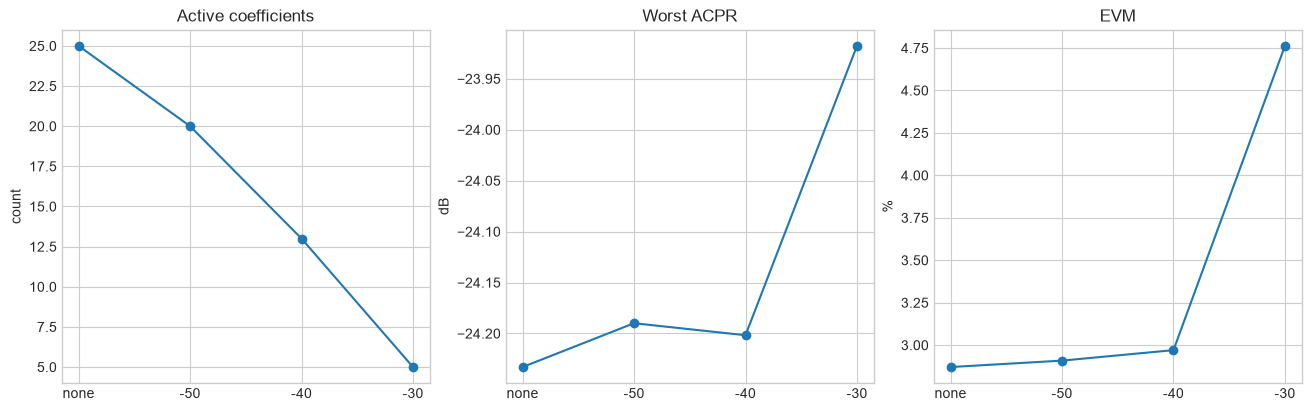

In [8]:
prune_thresholds = [None, -50, -40, -30]
prune_rows = []

for threshold in prune_thresholds:
    model, history = du.run_learning_workflow(
        waveform["five_carrier"],
        pa,
        cfg,
        indirect_iters = 2,
        direct_iters = 2,
        prune_threshold_db = threshold,
    )
    final_metrics = history[-1]
    prune_rows.append(
        {
            "threshold_db": -999.0 if threshold is None else float(threshold),
            "label": "none" if threshold is None else str(threshold),
            "num_coeffs": final_metrics["num_coeffs"],
            "acpr_db": final_metrics["acpr_db"],
            "evm_pct": final_metrics["evm_pct"],
            "nmse_db": final_metrics["nmse_db"],
        }
    )

print(du.rows_to_table(prune_rows))

fig, axes = plt.subplots(1, 3, figsize=(13,4), constrained_layout=True)
labels = [row["label"] for row in prune_rows]
axes[0].plot(labels, [row["num_coeffs"] for row in prune_rows], marker="o")
axes[0].set_title("Active coefficients")
axes[0].set_ylabel("count")

axes[1].plot(labels, [row["acpr_db"] for row in prune_rows], marker="o")
axes[1].set_title("Worst ACPR")
axes[1].set_ylabel("dB")

axes[2].plot(labels, [row["evm_pct"] for row in prune_rows], marker="o")
axes[2].set_title("EVM")
axes[2].set_ylabel("%")


In [9]:
observation_bw = 0.20
five_carrier_wf = waveform["five_carrier"]

naive_model, naive_history = du.run_learning_workflow(
    five_carrier_wf,
    pa,
    cfg,
    indirect_iters=2,
    direct_iters=2,
    observation_bw = observation_bw,
    basis_bandlimit_aware=False,
)

aware_model, aware_history = du.run_learning_workflow(
    five_carrier_wf,
    pa,
    cfg,
    indirect_iters=2,
    direct_iters=2,
    observation_bw=observation_bw,
    basis_bandlimit_aware=True,
)

bandwidth_rows = [
    {"case": "baseline_no_dpd", **du.evaluate_chain(five_carrier_wf.samples, five_carrier_wf, pa, None)},
    {"case": "naive_limited_feedback", **naive_history[-1]},
    {"case": "bandwidth_aware", **aware_history[-1]},
]

print(du.rows_to_table(bandwidth_rows))

case | papr_db | acpr_db | evm_pct | nmse_db | num_coeffs
--- | --- | --- | --- | --- | ---
baseline_no_dpd | 11.401 | -20.833 | 16.814 | -11.975 | 0.000
naive_limited_feedback | 7.594 | -24.217 | 3.700 | -23.383 | 25.000
bandwidth_aware | 8.694 | -24.407 | 3.004 | -25.011 | 25.000


## 7.Dedicated Versus Configuration-Robust DPD
The competition required one coefficient set to work across multiple unknown carrier configurations. The comparison below trains:

- a **dedicated** DPD using only the signle-carrier mask `00100`, and
- a **general** DPD using concatenated data from the single-carrier, three-carrier, and five-carrier masks.

This mirrors thepaper's main robustness argument: a single model may sacrifice some specialization, but it should generalize much better across changing signals.

waveform | model | papr_db | acpr_db | evm_pct | nmse_db | num_coeffs
--- | --- | --- | --- | --- | --- | ---
00100 | baseline | 9.381 | -21.569 | 20.918 | -12.086 | 0.000
00100 | dedicated_00100 | 5.829 | -27.625 | 2.664 | -29.572 | 25.000
00100 | general | 6.523 | -27.861 | 1.726 | -33.184 | 25.000
10110 | baseline | 9.751 | -21.714 | 13.165 | -12.584 | 0.000
10110 | dedicated_00100 | 17.398 | -14.073 | 17.644 | -8.803 | 25.000
10110 | general | 7.793 | -25.283 | 0.755 | -36.316 | 25.000
11111 | baseline | 10.416 | -20.972 | 15.562 | -12.335 | 0.000
11111 | dedicated_00100 | 18.192 | -10.246 | 27.048 | -5.561 | 25.000
11111 | general | 7.874 | -24.106 | 0.965 | -35.890 | 25.000


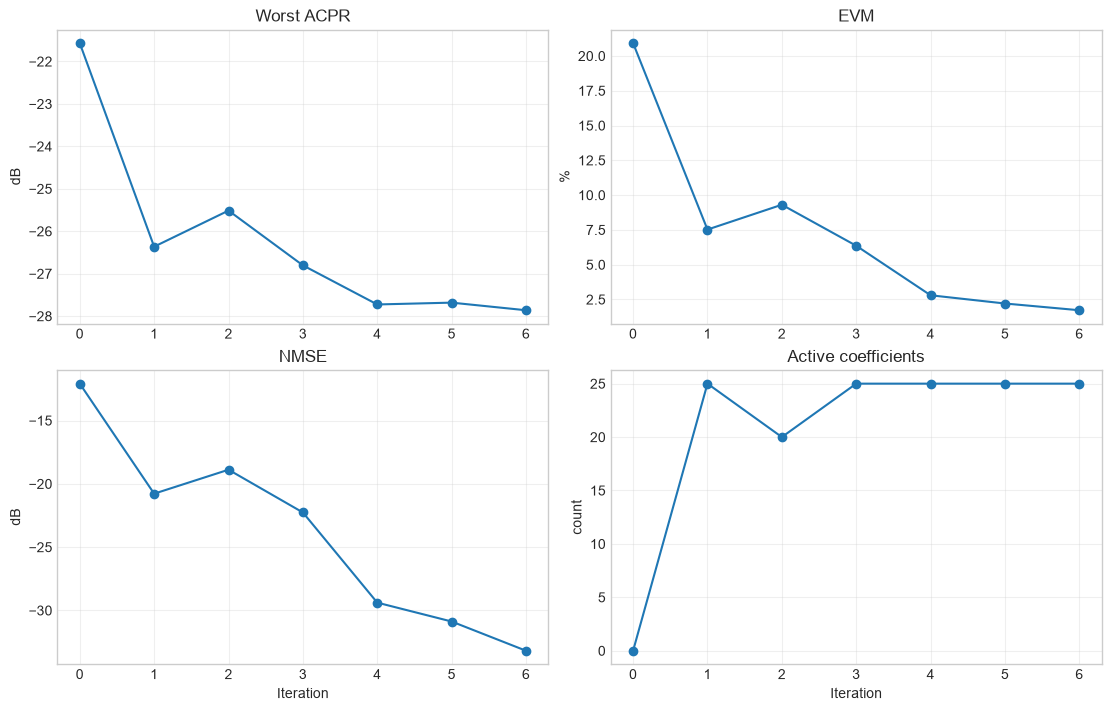

In [10]:
robust_train_waveforms =[
    du.generate_multicarrier_ofdm([0, 0, 1, 0, 0], du.make_rng(10), num_symbols=24),
    du.generate_multicarrier_ofdm([1, 0, 1, 1, 0], du.make_rng(11), num_symbols=24),
    du.generate_multicarrier_ofdm([1, 1, 1, 1, 1], du.make_rng(12), num_symbols=24),
]

# Dedicated model: trained only on the single-carrier case.
dedicated_model, dedicated_history = du.run_learning_workflow(
    robust_train_waveforms[0],
    pa,
    cfg,
    indirect_iters=3,
    direct_iters=3,
    prune_threshold_db=-50,
)

# General model: trained jointly across three representative masks
general_model, general_history = du.train_general_model(
    robust_train_waveforms,
    pa,
    cfg,
    indirect_iters=3,
    direct_iters=3,
    prune_threshold_db=-50,
)

rows = du.compare_models_on_waveforms(
    {
        "baseline": None,
        "dedicated_00100": dedicated_model,
        "general": general_model,
    },
    robust_train_waveforms,
    pa,
)

print(du.rows_to_table(rows))

_ = du.plot_learning_history(general_history)

## 8. Takeaways and Limits

This notebook is expected to show the following qualitative behavior:

- DPD improves ACPR, EVM, and NMSE relative to the undistorted baseline.
- Hybrid learning converges faster and more cleanly than indirect learning alone
- Moderate pruning can remove basis terms with little penalty
- Bandwidth-ware learning is safter than naive learning under filtered feedback
- A general DPD is much more robust than a dedicated model when the carrier mask change

What this notebook does **not** claim:

- exact reproduction of the paper's measured ACPR/ EVM tables,
- exact LMBA control-path delay optimization,
- reproduction of the competition score that depends on hardware power and efficiency measurements

Those limitations come from missing DUT data and the absence of a complete hardware-identifiable LMBA model in the paper text